In [1]:
# Import modules

import pandas as pd
import lightgbm as lgb
import time
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px


In [3]:

master_path = '../../../Master_v2.xlsx'
all_data = pd.read_excel(master_path)

print(all_data.head())

     price     priceper  year dateoftransfer         borough  postcode  \
0   490000  10208.33333  2022     2022-01-21  city of london  EC4A 1EP   
1   802500  10422.07792  2015     2015-10-16  city of london  EC1Y 0ST   
2  1200000  15189.87342  2019     2019-08-16  city of london  EC2Y 5AG   
3   626250  12780.61224  2015     2015-03-03  city of london  EC2Y 5AG   
4   938400  14436.92308  2015     2015-01-29  city of london  EC2Y 5AG   

                            transactionid  tfarea area_bin propertytype  ...  \
0  {DE2D0CDF-F797-51EE-E053-6C04A8C00671}    48.0       Q1            F  ...   
1  {23B6165E-9D97-FCF4-E050-A8C0620577FA}    77.0       Q2            F  ...   
2  {93E6821D-E5C2-40FD-E053-6B04A8C0C1DF}    79.0       Q3            F  ...   
3  {637497CC-ECF1-4AFD-B581-E63781F99F4B}    49.0       Q1            F  ...   
4  {74550953-773F-4D4F-A43E-1E79826CD95B}    65.0       Q2            F  ...   

    central       ptal  crime_lagged_1yr  cpih_lagged_1yr  \
0  0.190356  

In [4]:
#Handle missing values
initial_rows = len(all_data.index)
all_data = all_data.dropna()
print(f"Number of rows removed for NA: {initial_rows - len(all_data.index)}")


Number of rows removed for NA: 247500


In [5]:
#Remove outliers >2.0million
all_data = all_data.drop(all_data[all_data['price'] >= 2000000].index)
# all_data = all_data.drop(all_data[all_data['price'] <= 210000].index)

print(f"Total number of rows for train/test/validation: {len(all_data.index)}")

Total number of rows for train/test/validation: 581471


In [6]:
# Shuffle rows within years
all_data = all_data.groupby('year').apply(lambda x: x.sample(frac=1, random_state=42)).reset_index(drop=True)

/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/709444405.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  all_data = all_data.groupby('year').apply(lambda x: x.sample(frac=1, random_state=42)).reset_index(drop=True)


In [7]:
#Define features and target: Uses price as as target and area as predictor
# Create outward postcode (e.g., "SW1A") for location signal
all_data['outward_postcode'] = all_data['postcode'].str.split().str[0]

target = 'price'
features = ['tfarea', 'propertytype', 'duration', 'education', 'culture', 'central', 'ptal', 'crime_lagged_1yr', 'cpih_lagged_1yr', 'unemployment_lagged_1yr', 'mortgage_lagged_1yr', 'avg_price_lagged_1yr', 'borough', 'postcode', 'lat', 'long']
categorical_features = ['propertytype', 'duration', 'borough', 'postcode']

#Split into train/test based on time
test_data = all_data[all_data['year'] == 2024]
train_full = all_data.drop(all_data[all_data['year'] == 2024].index)
print(f"Length of test data {len(test_data)}")
print(f"Length of training data {len(train_full)}")

# Test split
X_test = test_data[features].copy()
# Convert categorical columns to category dtype (LightGBM requires category, not object/string)
for col in categorical_features:
    X_test[col] = X_test[col].astype('category')
Y_test = test_data[target]

# Train split
X_train_full = train_full[features].copy()
# Convert categorical columns to category dtype (LightGBM requires category, not object/string)
for col in categorical_features:
    X_train_full[col] = X_train_full[col].astype('category')
Y_train_full = train_full[target]

Length of test data 33598
Length of training data 547873


In [8]:
# Time series split function

def time_series_split(df, n_splits=5):
    """
    Generate train/validation splits at year boundaries
    """
    years = sorted(df['year'].unique())
    total_years = len(years)

    splits = []

    for i in range(n_splits):
        # Expanding training window
        train_end_year_idx = total_years - n_splits + i
        train_years = years[:train_end_year_idx]

        # Validation window
        val_start_idx = train_end_year_idx
        val_end_idx = val_start_idx + 1
        val_years = years[val_start_idx:val_end_idx]

        # Note down index, so that the list returned is not abhorrently large
        train_idx = df[df['year'].isin(train_years)].index.values
        val_idx = df[df['year'].isin(val_years)].index.values

        splits.append((train_idx, val_idx))

        print(f"Fold {i+1}: Train on {train_years[0]} to {train_years[-1]}"
              f"({len(train_years)} years, {len(train_idx):,} samples) "
              f"Validate on {val_years[0]} to {val_years[-1]}"
              f"({len(val_years)} years, {len(val_idx):,} samples)")
    
    return splits

In [9]:
# Segmentation thresholds
LOW_MAX = 250_000
HIGH_MIN = 1_100_000
segments = {
    "low": (-np.inf, LOW_MAX),
    "mid": (LOW_MAX, HIGH_MIN),
    "high": (HIGH_MIN, np.inf),
}

# Loss choice: Huber for tails, L2 for mid bulk
segment_loss = {
    "low": ("huber", 0.9),
    "mid": ("regression", None),
    "high": ("huber", 0.9),
}

# Prepare segment-specific training data
segment_data = {}
for name, (low, high) in segments.items():
    seg_train = train_full[(train_full[target] > low) & (train_full[target] <= high)].copy().reset_index(drop=True)

    X_train = seg_train[features].copy()
    for col in categorical_features:
        X_train[col] = X_train[col].astype("category")

    y_train = seg_train[target]

    segment_data[name] = {
        "train_df": seg_train,
        "X_train": X_train,
        "y_train": y_train,
    }

segment_data.keys()

dict_keys(['low', 'mid', 'high'])

In [10]:
# Fixed LightGBM parameters (from Optuna tuning)
fixed_params = {
    "n_estimators": 1011,
    "learning_rate": 0.010555203732718746,
    "num_leaves": 130,
    "max_depth": 18,
    "min_child_samples": 12,
    "subsample": 0.8753968850598899,
    "colsample_bytree": 0.5003753045491645,
    "random_state": 42,
    "verbosity": -1,
}

In [11]:
# Optuna tuning removed; use fixed parameters for all segments
segment_best_params = {name: fixed_params.copy() for name in segments}
# Placeholder to avoid downstream references
segment_studies = {name: None for name in segments}
segment_best_params

{'low': {'n_estimators': 1011,
  'learning_rate': 0.010555203732718746,
  'num_leaves': 130,
  'max_depth': 18,
  'min_child_samples': 12,
  'subsample': 0.8753968850598899,
  'colsample_bytree': 0.5003753045491645,
  'random_state': 42,
  'verbosity': -1},
 'mid': {'n_estimators': 1011,
  'learning_rate': 0.010555203732718746,
  'num_leaves': 130,
  'max_depth': 18,
  'min_child_samples': 12,
  'subsample': 0.8753968850598899,
  'colsample_bytree': 0.5003753045491645,
  'random_state': 42,
  'verbosity': -1},
 'high': {'n_estimators': 1011,
  'learning_rate': 0.010555203732718746,
  'num_leaves': 130,
  'max_depth': 18,
  'min_child_samples': 12,
  'subsample': 0.8753968850598899,
  'colsample_bytree': 0.5003753045491645,
  'random_state': 42,
  'verbosity': -1}}

In [12]:
# Train model per segment and generate test predictions

segment_models = {}
segment_metrics = []

# Pre-allocate combined predictions on full test set
Y_pred = pd.Series(index=test_data.index, dtype=float)

for name, (low, high) in segments.items():
    data = segment_data[name]
    loss, alpha = segment_loss[name]

    params = {**fixed_params, "objective": loss}
    if loss == "huber":
        params["alpha"] = alpha

    model = lgb.LGBMRegressor(**params)
    model.fit(
        data["X_train"],
        data["y_train"],
        categorical_feature=categorical_features,
    )

    # Predict on segment-specific test slice
    mask = (test_data[target] > low) & (test_data[target] <= high)
    X_test_seg = test_data.loc[mask, features].copy()
    for col in categorical_features:
        X_test_seg[col] = X_test_seg[col].astype("category")

    preds = model.predict(X_test_seg)
    Y_pred.loc[mask] = preds

    y_test_seg = test_data.loc[mask, target]
    segment_metrics.append(
        {
            "segment": name,
            "n_test": len(y_test_seg),
            "rmse": mean_squared_error(y_test_seg, preds, squared=False),
            "rmse as a percentage of mean price": mean_squared_error(y_test_seg, preds, squared=False) / y_test_seg.mean(),
            "mae": mean_absolute_error(y_test_seg, preds),
            "mae as a percentage of mean price": mean_absolute_error(y_test_seg, preds) / y_test_seg.mean(),
            "loss": loss,
        }
    )

    segment_models[name] = model

segment_metrics

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use 

[{'segment': 'low',
  'n_test': 2042,
  'rmse': 43590.439598933895,
  'rmse as a percentage of mean price': 0.2192400340318923,
  'mae': 35527.54728009674,
  'mae as a percentage of mean price': 0.17868736233044483,
  'loss': 'huber'},
 {'segment': 'mid',
  'n_test': 28994,
  'rmse': 92044.12323064907,
  'rmse as a percentage of mean price': 0.16852721943859483,
  'mae': 66090.62697648728,
  'mae as a percentage of mean price': 0.12100793841438871,
  'loss': 'regression'},
 {'segment': 'high',
  'n_test': 2562,
  'rmse': 238539.26732827618,
  'rmse as a percentage of mean price': 0.16656060704623685,
  'mae': 199017.74428394786,
  'mae as a percentage of mean price': 0.13896461019681225,
  'loss': 'huber'}]

In [13]:
# Fixed parameters used for all segments
for name in segments.keys():
    print(f"{name} params: {fixed_params}")

low params: {'n_estimators': 1011, 'learning_rate': 0.010555203732718746, 'num_leaves': 130, 'max_depth': 18, 'min_child_samples': 12, 'subsample': 0.8753968850598899, 'colsample_bytree': 0.5003753045491645, 'random_state': 42, 'verbosity': -1}
mid params: {'n_estimators': 1011, 'learning_rate': 0.010555203732718746, 'num_leaves': 130, 'max_depth': 18, 'min_child_samples': 12, 'subsample': 0.8753968850598899, 'colsample_bytree': 0.5003753045491645, 'random_state': 42, 'verbosity': -1}
high params: {'n_estimators': 1011, 'learning_rate': 0.010555203732718746, 'num_leaves': 130, 'max_depth': 18, 'min_child_samples': 12, 'subsample': 0.8753968850598899, 'colsample_bytree': 0.5003753045491645, 'random_state': 42, 'verbosity': -1}


In [14]:
# Linear calibration per segment (quick bias correction)

Y_pred_cal = Y_pred.copy()
calibration = {}

for name, (low, high) in segments.items():
    data = segment_data[name]
    preds_train = segment_models[name].predict(data["X_train"])
    y_train_seg = data["y_train"]

    b, a = np.polyfit(preds_train, y_train_seg, 1)  # y = a + b*x
    calibration[name] = {"a": a, "b": b}

    mask_test = (test_data[target] > low) & (test_data[target] <= high)
    Y_pred_cal.loc[mask_test] = a + b * Y_pred.loc[mask_test]

Y_pred = Y_pred_cal
calibration


{'low': {'a': -1610995163.7738364, 'b': 8032.86298519007},
 'mid': {'a': -14745.190819423093, 'b': 1.0285329920521558},
 'high': {'a': -62656287655.93077, 'b': 44229.89817129552}}

In [15]:
# Evaluate overall performance
rmse = mean_squared_error(Y_test, Y_pred, squared=False)
mean_price = Y_test.mean()
rmse_relative = (rmse / mean_price) * 100
mae = mean_absolute_error(Y_test, Y_pred)
mae_relative = (mae / mean_price) * 100
r2 = r2_score(Y_test, Y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"Mean price: {mean_price:.2f}")
print(f"RMSE as percentage of mean price: {rmse_relative:.2f}%")
print(f"MAE: {mae:.2f}")
print(f"MAE as percentage of mean price: {mae_relative:.2f}%")
print(f"R-squared: {r2:.2f}")

pd.DataFrame(segment_metrics)

RMSE: 101416.41
Mean price: 592617.05
RMSE as percentage of mean price: 17.11%
MAE: 70314.36
MAE as percentage of mean price: 11.87%
R-squared: 0.90


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:483: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


,segment,n_test,rmse,rmse as a percentage of mean price,mae,mae as a percentage of mean price,loss
0,low,2042,43590.439599,0.219240,35527.547280,0.178687,huber
1,mid,28994,92044.123231,0.168527,66090.626976,0.121008,regression
2,high,2562,238539.267328,0.166561,199017.744284,0.138965,huber


In [16]:
# Calculate tolerance levels
percentage_errors = np.abs((Y_test - Y_pred) / Y_test) * 100

tolerances = [5, 10, 15, 20]

for tol in tolerances:
    within_tol = (percentage_errors <= tol).sum()
    pct = (within_tol / len(Y_test)) * 100
    print(f"Within {tol:2d}%: {pct:5.1f}% ({within_tol}/{len(Y_test)} properties)")



Within  5%:  27.9% (9375/33598 properties)
Within 10%:  52.6% (17660/33598 properties)
Within 15%:  70.7% (23764/33598 properties)
Within 20%:  82.6% (27760/33598 properties)


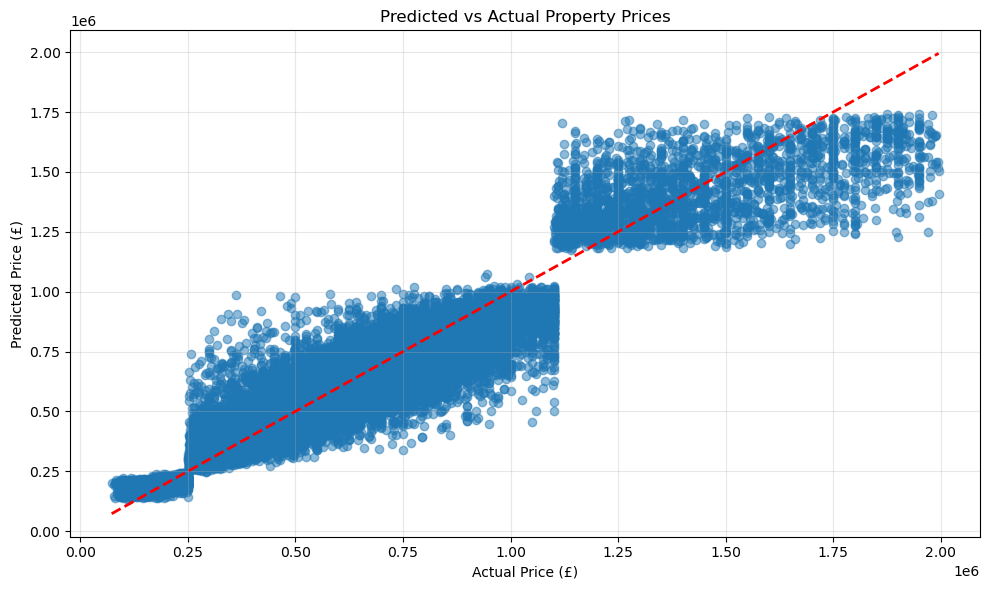

In [17]:
# Plot predicted vs actual
plt.figure(figsize=(10, 6))
plt.scatter(Y_test, Y_pred, alpha=0.5)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)  # perfect prediction line
plt.xlabel('Actual Price (£)')
plt.ylabel('Predicted Price (£)')
plt.title('Predicted vs Actual Property Prices')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Feature importance for low segment:


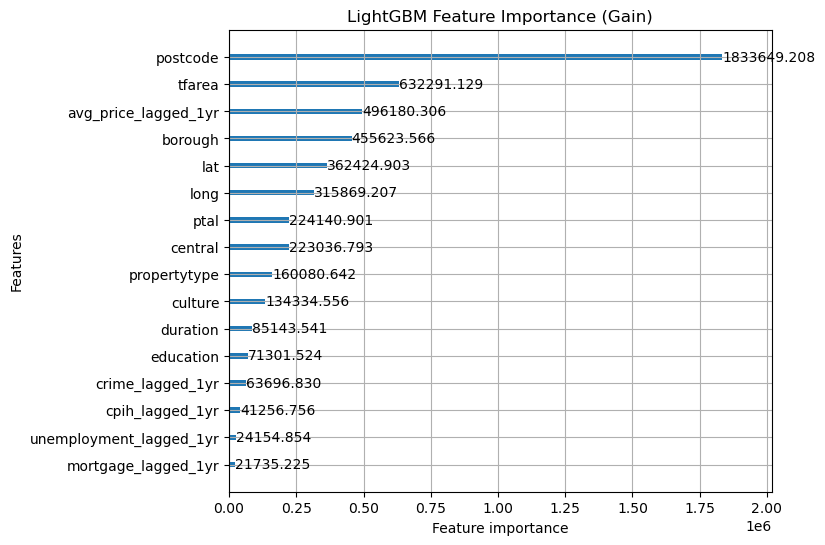

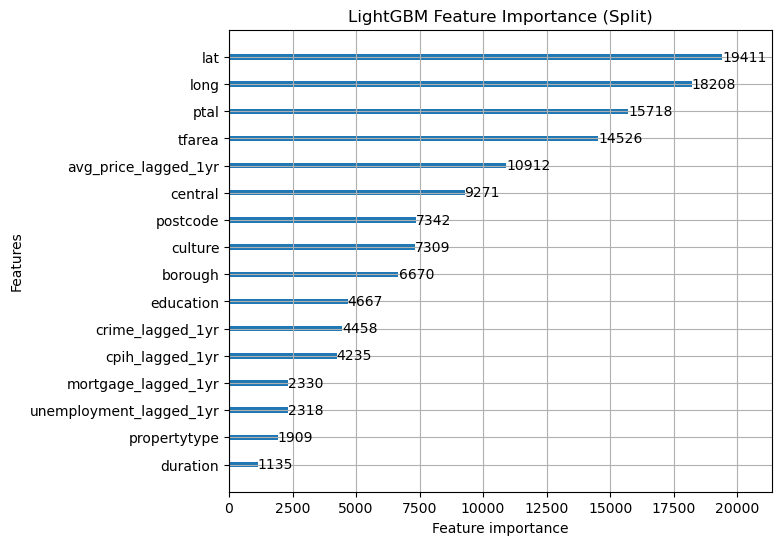

Feature importance for mid segment:


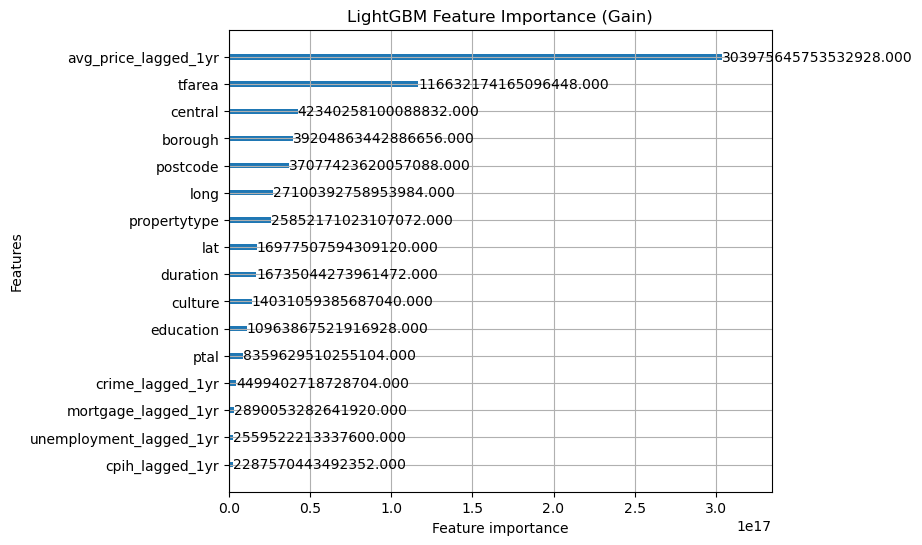

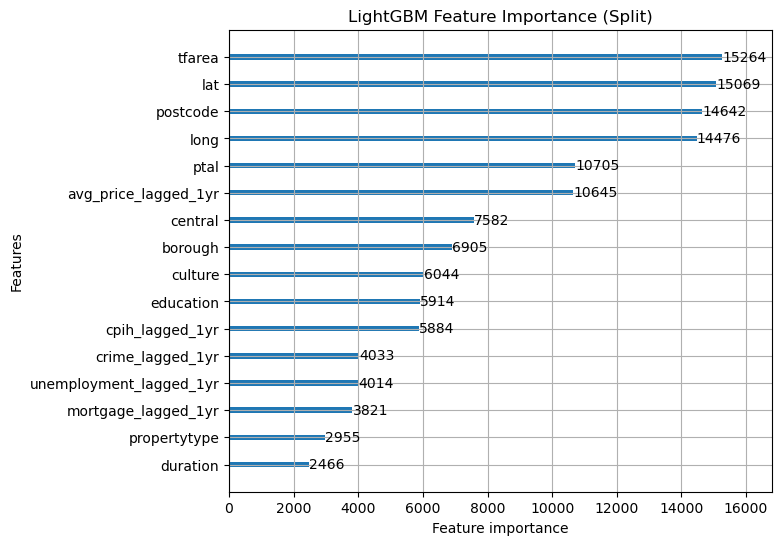

Feature importance for high segment:


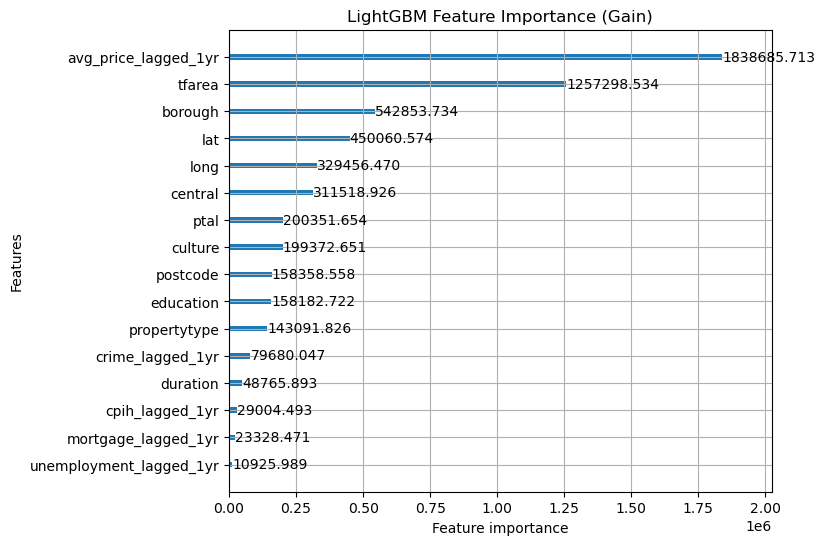

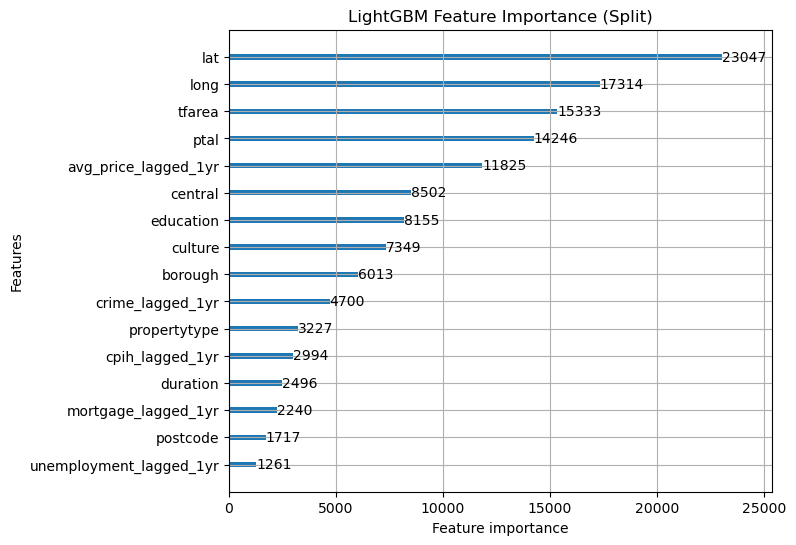

In [18]:
for name, (low, high) in segments.items():
    study = segment_studies[name]
    best_model = segment_models[name]

    print(f"Feature importance for {name} segment:")

    #Feature importance (Gain)
    lgb.plot_importance(best_model, importance_type="gain", figsize=(7,6), title="LightGBM Feature Importance (Gain)")
    plt.show()

    # Feature importance (Split)
    lgb.plot_importance(best_model, importance_type="split", figsize=(7,6), title="LightGBM Feature Importance (Split)")
    plt.show()

In [19]:
# Build results dataframe for error analysis

results_df = (
    test_data[["tfarea", "year", "postcode", "price", "propertytype"]]
    .copy()
    .join(pd.Series(Y_pred, index=test_data.index, name="predictedprice"))
)
results_df = results_df.rename(columns={"price": "actualprice"})

# compute absolute percentage error
results_df["ape"] = (results_df.actualprice - results_df.predictedprice).abs() / results_df.actualprice

# compute signed percentage error
results_df["spe"] = (results_df.actualprice - results_df.predictedprice) / results_df.actualprice

# segment label for analysis
results_df["segment"] = pd.cut(
    results_df.actualprice,
    bins=[0, LOW_MAX, HIGH_MIN, np.inf],
    labels=["low", "mid", "high"],
    include_lowest=True,
)

results_df.head()

,tfarea,year,postcode,actualprice,propertytype,predictedprice,ape,spe,segment
547873,72.0,2024,CR0 1TZ,275000,F,333963.566173,0.214413,-0.214413,mid
547874,82.0,2024,SE28 8PF,380000,T,385634.477837,0.014828,-0.014828,mid
547875,101.0,2024,TW11 9EX,650000,T,799004.903988,0.229238,-0.229238,mid
547876,65.0,2024,HA5 5JS,380000,F,355635.138184,0.064118,0.064118,mid
547877,88.0,2024,NW11 9LT,555000,F,570090.131082,0.027189,-0.027189,mid


In [20]:
# SPE by property type (overall + within segments)

spe_by_type = (
    results_df.groupby("propertytype")["spe"]
    .agg(n="size", spe_mean="mean", spe_median="median", spe_std="std")
    .sort_values("spe_mean")
)

spe_by_type

spe_by_type_segment = (
    results_df.groupby(["segment", "propertytype"])["spe"]
    .agg(n="size", spe_mean="mean", spe_median="median", spe_std="std")
    .reset_index()
    .sort_values(["segment", "spe_mean"])
)

spe_by_type_segment


/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/3046675357.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results_df.groupby(["segment", "propertytype"])["spe"]


,segment,propertytype,n,spe_mean,spe_median,spe_std
0,low,D,2,-0.731873,-0.731873,1.159895
1,low,F,1916,-0.057423,0.026515,0.273338
3,low,T,107,-0.037314,0.015565,0.242846
2,low,S,17,-0.019095,0.009950,0.089608
5,mid,F,12291,-0.028136,-0.009630,0.185950
4,mid,D,1337,-0.011287,0.008146,0.174049
6,mid,S,5759,-0.006639,0.009470,0.164629
7,mid,T,9607,0.004298,0.023138,0.163603
9,high,F,410,-0.035057,-0.026751,0.141908
8,high,D,456,-0.001565,-0.007234,0.138989


In [21]:
# Error distribution (APE)
results_df["ape"].describe()

count    33598.000000
mean         0.125204
std          0.129761
min          0.000001
25%          0.044634
50%          0.094175
75%          0.165200
max          1.867125
Name: ape, dtype: float64

In [22]:
# Error distribution (SPE)
results_df["spe"].describe()

count    33598.000000
mean        -0.014370
std          0.179744
min         -1.867125
25%         -0.093754
50%          0.006922
75%          0.094625
max          0.567755
Name: spe, dtype: float64

In [23]:
# Error summary by segment
results_df.groupby("segment")[["ape", "spe"]].agg(["mean", "median", "std"])

/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/3519657844.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results_df.groupby("segment")[["ape", "spe"]].agg(["mean", "median", "std"])


ape                           spe                    
             mean    median       std      mean    median       std
segment                                                            
low      0.178566  0.116583  0.213731 -0.056711  0.025425  0.272699
mid      0.123064  0.093087  0.124559 -0.012342  0.006744  0.174665
high     0.106888  0.091421  0.078641 -0.003565 -0.003351  0.132670

In [24]:
# Segment sizes
results_df["segment"].value_counts().sort_index()

segment
low      2042
mid     28994
high     2562
Name: count, dtype: int64

In [25]:
fig = px.histogram(results_df, x='ape', nbins=80, log_y=False)
fig.update_layout(
    xaxis_title='Absolute Percentage Error (APE)',
    yaxis_title='Count'
)
fig.show()

In [26]:
# RMSE by APE decile

results_df["ape_decile"] = pd.qcut(results_df.ape, 10, labels=False)

rmse_by_decile = (
    results_df.groupby("ape_decile")
      .apply(lambda x: np.sqrt(((x.actualprice - x.predictedprice) ** 2).mean()))
)

decile_summary = (
    results_df.groupby("ape_decile")
    .agg(
        n=("ape", "size"),
        ape_min=("ape", "min"),
        ape_max=("ape", "max"),
        ape_mean=("ape", "mean"),
    )
    .join(rmse_by_decile.rename("rmse"))
)

decile_summary


/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/1647132127.py:7: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,n,ape_min,ape_max,ape_mean,rmse
ape_decile,,,,,
0,3360,0.000001,0.017596,0.008753,6628.418010
1,3360,0.017601,0.035364,0.026353,17390.485540
2,3360,0.035379,0.053863,0.044598,29633.236733
3,3359,0.053873,0.073271,0.063333,41918.235070
4,3360,0.073272,0.094174,0.083447,58541.313831
5,3360,0.094176,0.118037,0.105826,72435.369832
6,3359,0.118065,0.147458,0.132080,93652.896354
7,3360,0.147469,0.186574,0.165846,118132.664702
8,3360,0.186624,0.253923,0.216258,156110.270972


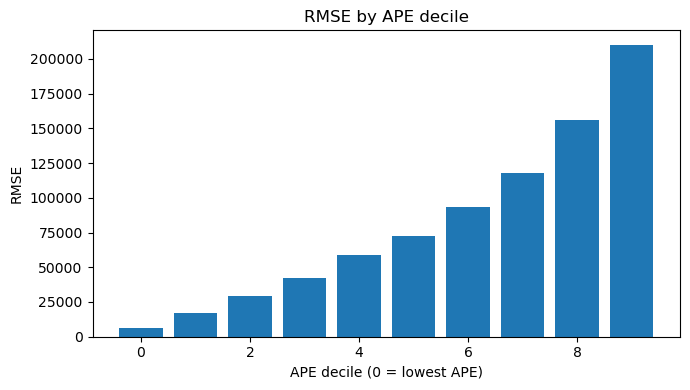

In [27]:
plt.figure(figsize=(7,4))
plt.bar(decile_summary.index, decile_summary["rmse"])
plt.xlabel("APE decile (0 = lowest APE)")
plt.ylabel("RMSE")
plt.title("RMSE by APE decile")
plt.tight_layout()
plt.show()

In [28]:
# Error by price bins

results_df['price_bin'] = pd.qcut(results_df.actualprice, 20, labels=False)
pricebins = results_df.groupby('price_bin')['ape'].mean()
pricebins

price_bin
0     0.182559
1     0.201178
2     0.169486
3     0.143738
4     0.118598
5     0.111049
6     0.105127
7     0.107320
8     0.104379
9     0.111937
10    0.103584
11    0.113787
12    0.111955
13    0.115374
14    0.110891
15    0.115495
16    0.114394
17    0.120590
18    0.138662
19    0.098943
Name: ape, dtype: float64

In [29]:
results_df['price_bin'] = pd.qcut(results_df.actualprice, 20, labels=False)
pricebins = results_df.groupby('price_bin')['spe'].mean()
pricebins

price_bin
0    -0.098053
1    -0.137742
2    -0.145190
3    -0.111060
4    -0.074362
5    -0.058128
6    -0.035559
7    -0.027768
8    -0.007600
9    -0.014402
10    0.012423
11    0.017575
12    0.027443
13    0.027717
14    0.037096
15    0.053477
16    0.078610
17    0.110913
18    0.011337
19    0.056681
Name: spe, dtype: float64

In [30]:
results_df["area_q"] = pd.qcut(results_df.tfarea, 20, labels=False)

areabins = results_df.groupby("area_q")["ape"].mean()
areabins


area_q
0     0.137256
1     0.137198
2     0.131544
3     0.125983
4     0.128964
5     0.130968
6     0.124941
7     0.125365
8     0.128437
9     0.124738
10    0.127392
11    0.126703
12    0.122830
13    0.121227
14    0.118500
15    0.124326
16    0.119510
17    0.116666
18    0.115738
19    0.113774
Name: ape, dtype: float64

In [31]:
results_df["area_q"] = pd.qcut(results_df.tfarea, 20, labels=False)

areabins = results_df.groupby("area_q")["spe"].mean()
areabins

area_q
0    -0.030658
1    -0.023944
2    -0.024967
3    -0.007669
4     0.001613
5    -0.025400
6    -0.011518
7    -0.010503
8    -0.002994
9    -0.015468
10   -0.022104
11   -0.009744
12   -0.009549
13   -0.001473
14    0.003954
15   -0.029779
16   -0.006829
17   -0.019096
18   -0.023074
19   -0.010938
Name: spe, dtype: float64

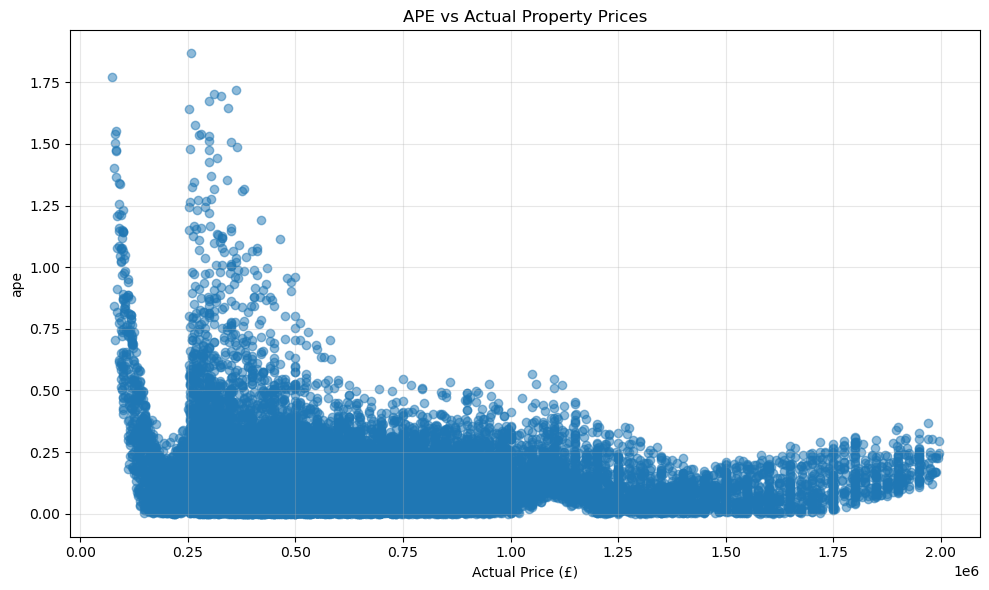

In [32]:
# Plot predicted vs actual
plt.figure(figsize=(10, 6))
plt.scatter(results_df['actualprice'], results_df['ape'], alpha=0.5)
# plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)  # perfect prediction line
plt.xlabel('Actual Price (£)')
plt.ylabel('ape')
plt.title('APE vs Actual Property Prices')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

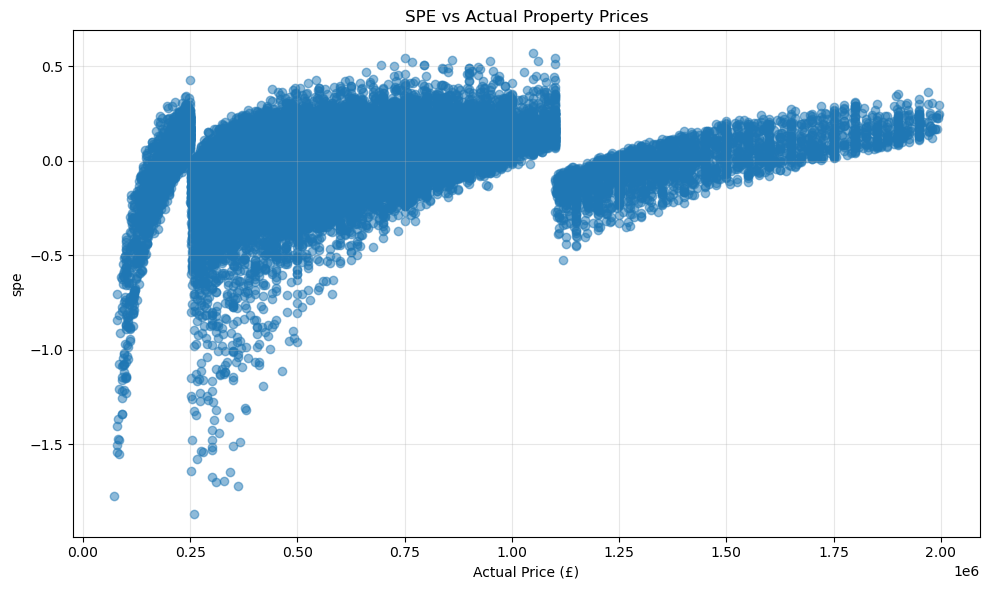

In [33]:
# Plot predicted vs actual
plt.figure(figsize=(10, 6))
plt.scatter(results_df['actualprice'], results_df['spe'], alpha=0.5)
# plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', lw=2)  # perfect prediction line
plt.xlabel('Actual Price (£)')
plt.ylabel('spe')
plt.title('SPE vs Actual Property Prices')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:

fig = px.histogram(all_data, x='price', nbins=120, title='Actual Price Distribution')
fig.show()

/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/1368177397.py:6: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



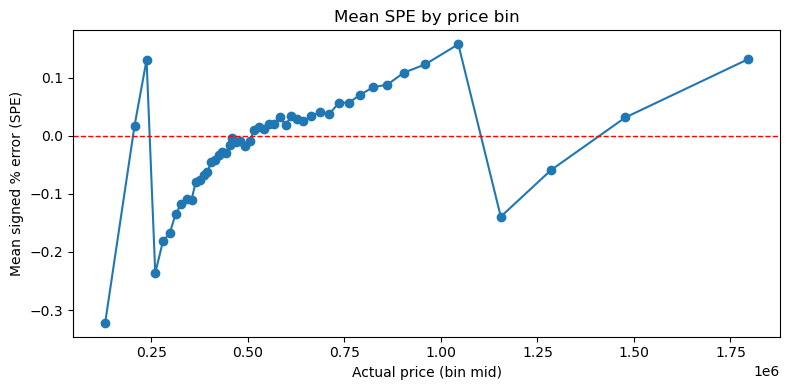

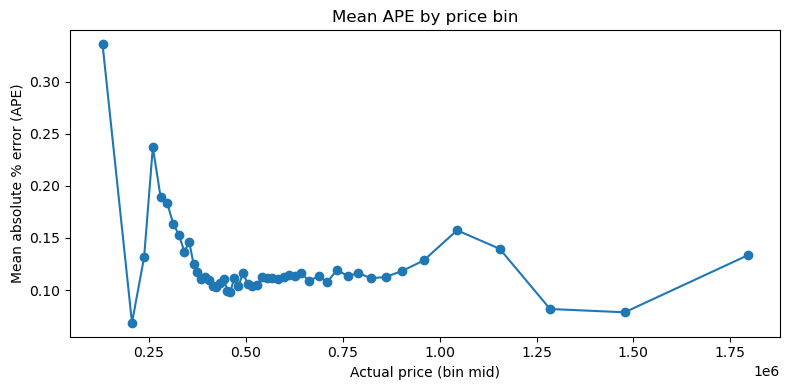

,n,spe_mean,spe_std,ape_mean,mid,spe_sign
actualprice,,,,,,
"(72999.999, 187500.0]",676,-0.322009,0.317909,0.335938,1.302500e+05,-1.0
"(187500.0, 225000.0]",670,0.016498,0.087222,0.068611,2.062500e+05,1.0
"(250000.0, 270000.0]",647,-0.236409,0.236865,0.237072,2.600000e+05,-1.0
"(510000.0, 522500.0]",575,0.009457,0.135433,0.103884,5.162500e+05,1.0
"(1100000.0, 1210000.0]",550,-0.139450,0.089463,0.139634,1.155000e+06,-1.0
"(1360000.0, 1595000.0]",658,0.031210,0.090581,0.078705,1.477500e+06,1.0


In [35]:
# Exploratory: SPE/APE by price bins to choose segmentation points

price_bins = pd.qcut(results_df.actualprice, q=50, duplicates='drop')

bin_summary = (
    results_df.groupby(price_bins)
    .agg(
        n=("spe", "size"),
        spe_mean=("spe", "mean"),
        spe_std=("spe", "std"),
        ape_mean=("ape", "mean"),
    )
)

bin_summary["mid"] = bin_summary.index.map(lambda x: x.mid)

bin_summary

plt.figure(figsize=(8, 4))
plt.plot(bin_summary["mid"], bin_summary["spe_mean"], marker="o")
plt.axhline(0, color="r", linestyle="--", linewidth=1)
plt.xlabel("Actual price (bin mid)")
plt.ylabel("Mean signed % error (SPE)")
plt.title("Mean SPE by price bin")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(bin_summary["mid"], bin_summary["ape_mean"], marker="o")
plt.xlabel("Actual price (bin mid)")
plt.ylabel("Mean absolute % error (APE)")
plt.title("Mean APE by price bin")
plt.tight_layout()
plt.show()

# Candidate split points where mean SPE changes sign
bin_summary.assign(spe_sign=np.sign(bin_summary.spe_mean)).loc[
    lambda d: d.spe_sign.diff().ne(0)
]


In [36]:
# list of intervals (each interval is the price range)
bin_table = (
    bin_summary
    .assign(price_range=bin_summary.index.astype(str))
    .loc[:, ["price_range", "spe_mean", "spe_std"]]
    .assign(
        spe_min=results_df.groupby(price_bins)["spe"].min().values,
        spe_max=results_df.groupby(price_bins)["spe"].max().values,
    )
    .reset_index(drop=True)
)

bin_table

/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/625367472.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/var/folders/_6/n4f9pfd14lv1q8nl3892x2v80000gn/T/ipykernel_22887/625367472.py:8: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,price_range,spe_mean,spe_std,spe_min,spe_max
0,"(72999.999, 187500.0]",-0.322009,0.317909,-1.772535,0.238878
1,"(187500.0, 225000.0]",0.016498,0.087222,-0.253922,0.311993
2,"(225000.0, 250000.0]",0.130489,0.064698,-0.060282,0.426029
3,"(250000.0, 270000.0]",-0.236409,0.236865,-1.867125,0.042166
4,"(270000.0, 290000.0]",-0.181654,0.214847,-1.538838,0.107104
5,"(290000.0, 305000.0]",-0.167796,0.235378,-1.672296,0.168543
6,"(305000.0, 320000.0]",-0.135387,0.209043,-1.700596,0.169952
7,"(320000.0, 334976.0]",-0.117520,0.204727,-1.696057,0.204543
8,"(334976.0, 348000.0]",-0.109594,0.175356,-1.644775,0.237885
9,"(348000.0, 360000.0]",-0.110169,0.194534,-1.509373,0.224913
